<a href="https://colab.research.google.com/github/Tetraezar/Praktikum-Learning-AVD/blob/main/PraktikumLearningAVD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# 1. Memuat Data
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Membaca dataset
df = pd.read_csv("winequality-red.csv", sep=",")

# Melihat 5 data pertama
print(df.head())

# Melihat jumlah baris dan kolom
print("Ukuran data:", df.shape)

# Melihat nama kolom dan tipe data
print(df.info())

# Melihat ringkasan statistik
print(df.describe())

   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  
0      9.4        5  
1      9.8        5  
2      9.8        5 

In [ ]:

# DATA QUALITY CHECK
# 1. Memeriksa jumlah data kosong
missing_values = df.isnull().sum().sum()
# 2. Memeriksa jumlah data duplikat
data_duplikat = df.duplicated().sum()
# 3. Memeriksa data yang tidak sesuai
# Memeriksa apakah ada nilai selain angka pada kolom numerik
data_tidak_sesuai = df.select_dtypes(include="number").isna().sum().sum()
# 4. Menampilkan hasil pemeriksaan
print("====================================")
print("         DATA QUALITY CHECK")
print("====================================")
print("Jumlah Baris Dataset :", len(df))
print("Jumlah Kolom Dataset :", len(df.columns))
print("\nA. HASIL PEMERIKSAAN")
print("------------------------------------")
print("Missing Values       :", missing_values)
print("Data Duplikat        :", data_duplikat)
print("Data Tidak Sesuai    :", data_tidak_sesuai)
print("Perubahan Data       : Tidak dilakukan")
# 5. Menentukan status dataset
if missing_values == 0 and data_tidak_sesuai == 0:
    status = "Siap dianalisis"
else:
    status = "Perlu pemeriksaan lebih lanjut"

print("------------------------------------")
print("Status Dataset       :", status)
print("====================================")


         DATA QUALITY CHECK
Jumlah Baris Dataset : 1359
Jumlah Kolom Dataset : 12

A. HASIL PEMERIKSAAN
------------------------------------
Missing Values       : 0
Data Duplikat        : 0
Data Tidak Sesuai    : 0
Perubahan Data       : Tidak dilakukan
------------------------------------
Status Dataset       : Siap dianalisis


In [ ]:
# 1. Membersihkan Data

# Memeriksa data kosong
print("Data kosong:")
print(df.isnull().sum())

# Memeriksa jumlah baris duplikat
print("Duplikat:", df.duplicated().sum())

# Menghapus baris duplikat
df = df.drop_duplicates()

# Memeriksa hasil pembersihan
print("Ukuran data setelah dibersihkan:", df.shape)
print("Jumlah duplikat setelah dibersihkan:",
      df.duplicated().sum())

Data kosong:
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
dtype: int64
Duplikat: 0
Ukuran data setelah dibersihkan: (1359, 12)
Jumlah duplikat setelah dibersihkan: 0


In [ ]:

# DESCRIPTIVE STATISTICAL ANALYSIS

# 1. Menghitung statistik deskriptif
total_data = len(df)
mean_alcohol = df["alcohol"].mean()
median_alcohol = df["alcohol"].median()
mode_quality = df["quality"].mode()[0]
jumlah_quality_5 = (df["quality"] == 5).sum()

# Statistik tambahan
minimum_alcohol = df["alcohol"].min()
maksimum_alcohol = df["alcohol"].max()
std_alcohol = df["alcohol"].std()
q1_alcohol = df["alcohol"].quantile(0.25)
q3_alcohol = df["alcohol"].quantile(0.75)

# 2. Menampilkan hasil
print("======================================")
print("   DESCRIPTIVE STATISTICAL ANALYSIS")
print("======================================")

print("\n1. Total Data:", total_data, "baris")
print("   Jumlah seluruh sampel wine.")

print("\n2. Mean Alcohol:", round(mean_alcohol, 2), "%")
print("   Rata-rata kadar alkohol dalam wine.")

print("\n3. Median Alcohol:", round(median_alcohol, 2), "%")
print("   Nilai tengah kadar alkohol.")

print("\n4. Quality Terbanyak:", mode_quality)
print("   Skor kualitas yang paling sering muncul.")

print("\n5. Jumlah Quality 5:", jumlah_quality_5)
print("   Jumlah sampel wine dengan kualitas 5.")

print("======================================")


   DESCRIPTIVE STATISTICAL ANALYSIS

1. Total Data: 1359 baris
   Jumlah seluruh sampel wine.

2. Mean Alcohol: 10.43 %
   Rata-rata kadar alkohol dalam wine.

3. Median Alcohol: 10.2 %
   Nilai tengah kadar alkohol.

4. Quality Terbanyak: 5
   Skor kualitas yang paling sering muncul.

5. Jumlah Quality 5: 577
   Jumlah sampel wine dengan kualitas 5.


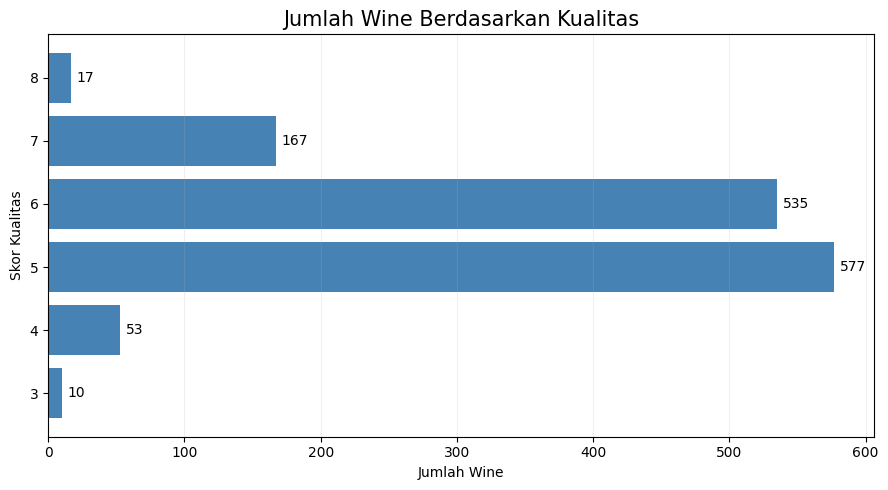

In [ ]:
# Grafik 1 jumlah wine berdasarkan kualitas

jumlah = df["quality"].value_counts().sort_index()

plt.figure(figsize=(9, 5))

bars = plt.barh(
    jumlah.index.astype(str),
    jumlah.values,
    color="steelblue"
)

plt.title("Jumlah Wine Berdasarkan Kualitas",
          fontsize=15)
plt.xlabel("Jumlah Wine")
plt.ylabel("Skor Kualitas")

plt.bar_label(bars, padding=4)
plt.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()



   alcohol kelompok_alkohol
0      9.4          [9, 10)
1      9.8          [9, 10)
2      9.8          [9, 10)
3      9.8          [9, 10)
5      9.4          [9, 10)


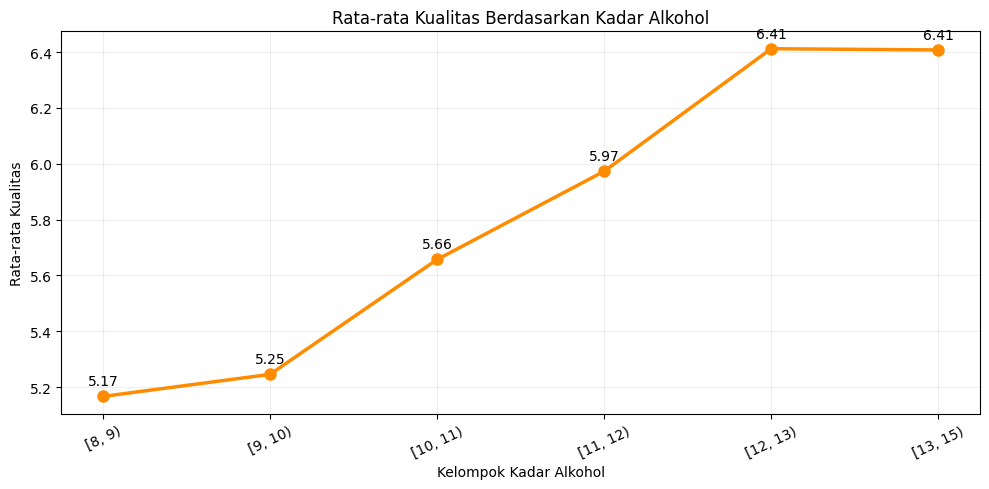

In [ ]:
# Grafik 2 — Line chart: kadar alkohol dan rata-rata kualitas

# Membuat kelompok kadar alkohol

df["kelompok_alkohol"] = pd.cut(
    df["alcohol"],
    bins=[8, 9, 10, 11, 12, 13, 15],
    right=False
)

# Melihat hasil pengelompokan
print(df[["alcohol", "kelompok_alkohol"]].head())
rata_kualitas = df.groupby(
    "kelompok_alkohol",
    observed=False
)["quality"].mean().dropna()

plt.figure(figsize=(10, 5))

plt.plot(
    rata_kualitas.index.astype(str),
    rata_kualitas.values,
    marker="o",
    markersize=8,
    linewidth=2.5,
    color="darkorange"
)

for i, nilai in enumerate(rata_kualitas.values):
    plt.text(
        i, nilai + 0.04,
        f"{nilai:.2f}",
        ha="center"
    )

plt.title("Rata-rata Kualitas Berdasarkan Kadar Alkohol")
plt.xlabel("Kelompok Kadar Alkohol")
plt.ylabel("Rata-rata Kualitas")
plt.xticks(rotation=25)
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()



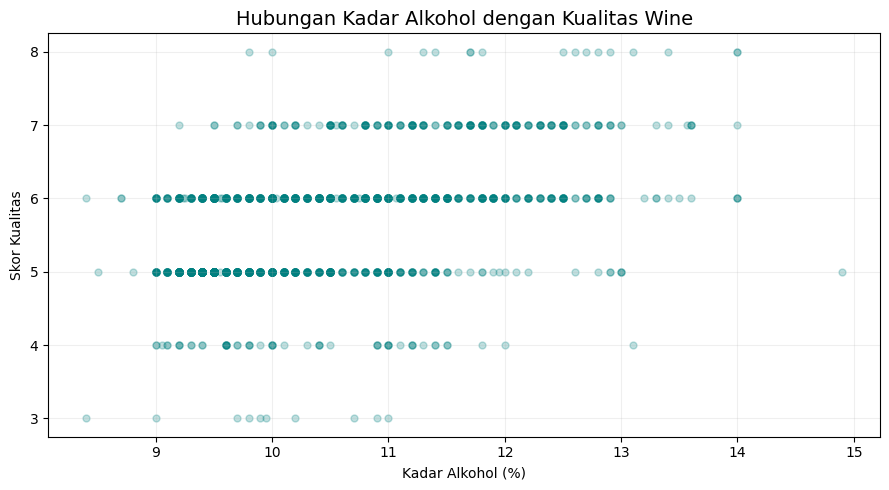

In [ ]:
# Grafik 3 — Scatter plot: kadar alkohol dan kualitas


plt.figure(figsize=(9, 5))

plt.scatter(
    df["alcohol"],
    df["quality"],
    alpha=0.25,
    s=25,
    color="teal"
)

plt.title("Hubungan Kadar Alkohol dengan Kualitas Wine",
          fontsize=14)
plt.xlabel("Kadar Alkohol (%)")
plt.ylabel("Skor Kualitas")

plt.yticks(sorted(df["quality"].unique()))
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()



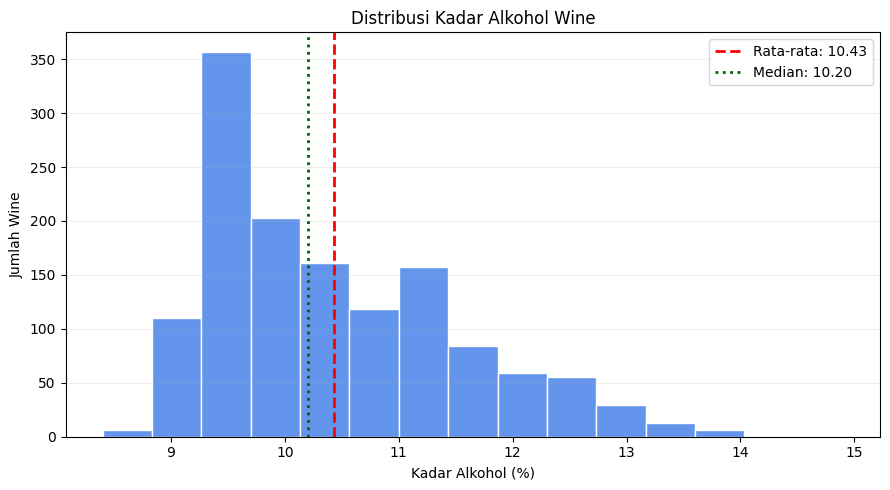

In [ ]:
# Grafik 4 — Histogram: distribusi kadar alkohol


rata = df["alcohol"].mean()
median = df["alcohol"].median()

plt.figure(figsize=(9, 5))

plt.hist(
    df["alcohol"],
    bins=15,
    color="cornflowerblue",
    edgecolor="white"
)

plt.axvline(
    rata,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Rata-rata: {rata:.2f}"
)

plt.axvline(
    median,
    color="darkgreen",
    linestyle=":",
    linewidth=2,
    label=f"Median: {median:.2f}"
)

plt.title("Distribusi Kadar Alkohol Wine")
plt.xlabel("Kadar Alkohol (%)")
plt.ylabel("Jumlah Wine")
plt.legend()
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()



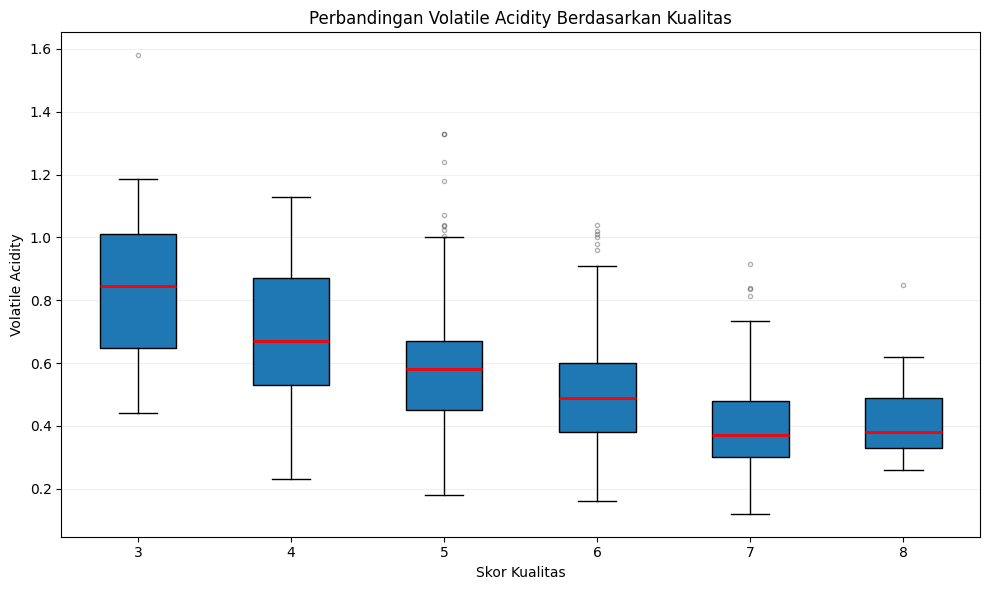

In [ ]:
s# Grafik 5 — Boxplot: kadar asam volatil berdasarkan kualitas


plt.figure(figsize=(10, 6))

data_box = [
    df.loc[
        df["quality"] == skor,
        "volatile acidity"
    ]
    for skor in sorted(df["quality"].unique())
]

plt.boxplot(
    data_box,
    tick_labels=sorted(df["quality"].unique()),
    patch_artist=True,
    showfliers=True,
    medianprops=dict(color="red", linewidth=2),
    flierprops=dict(
        marker="o",
        markersize=3,
        alpha=0.3
    )
)

plt.title("Perbandingan Volatile Acidity Berdasarkan Kualitas")
plt.xlabel("Skor Kualitas")
plt.ylabel("Volatile Acidity")
plt.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()




Q1: 0.55
Q3: 0.73
IQR: 0.17999999999999994
Batas bawah: 0.28000000000000014
Batas atas: 0.9999999999999999
Jumlah calon outlier: 55
    sulphates  quality
13       1.56        5
17       1.28        5
19       1.08        6
43       1.20        5
79       1.12        4
81       1.28        5
83       1.14        5
86       1.95        6
88       1.22        5
92       1.98        5


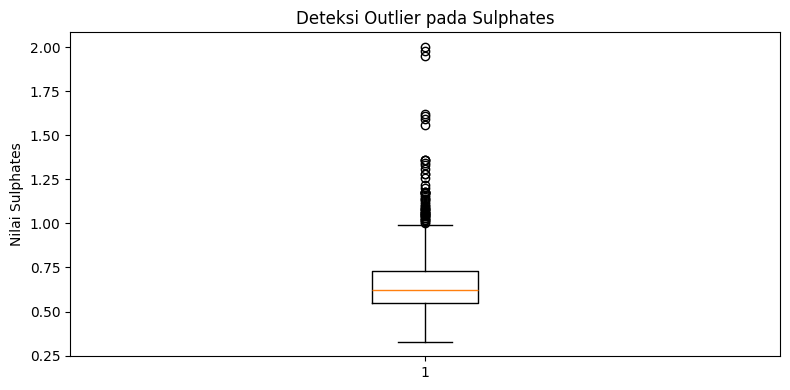

In [ ]:
# Tahap kelima — Mendeteksi outlier menggunakan IQR
kolom = "sulphates"

q1 = df[kolom].quantile(0.25)
q3 = df[kolom].quantile(0.75)
iqr = q3 - q1

batas_bawah = q1 - 1.5 * iqr
batas_atas = q3 + 1.5 * iqr

outlier = df[
    (df[kolom] < batas_bawah) |
    (df[kolom] > batas_atas)
]

print("Q1:", q1)
print("Q3:", q3)
print("IQR:", iqr)
print("Batas bawah:", batas_bawah)
print("Batas atas:", batas_atas)
print("Jumlah calon outlier:", len(outlier))

print(outlier[["sulphates", "quality"]].head(10))

plt.figure(figsize=(8, 4))
plt.boxplot(df[kolom])

plt.title("Deteksi Outlier pada Sulphates")
plt.ylabel("Nilai Sulphates")
plt.tight_layout()
plt.show()


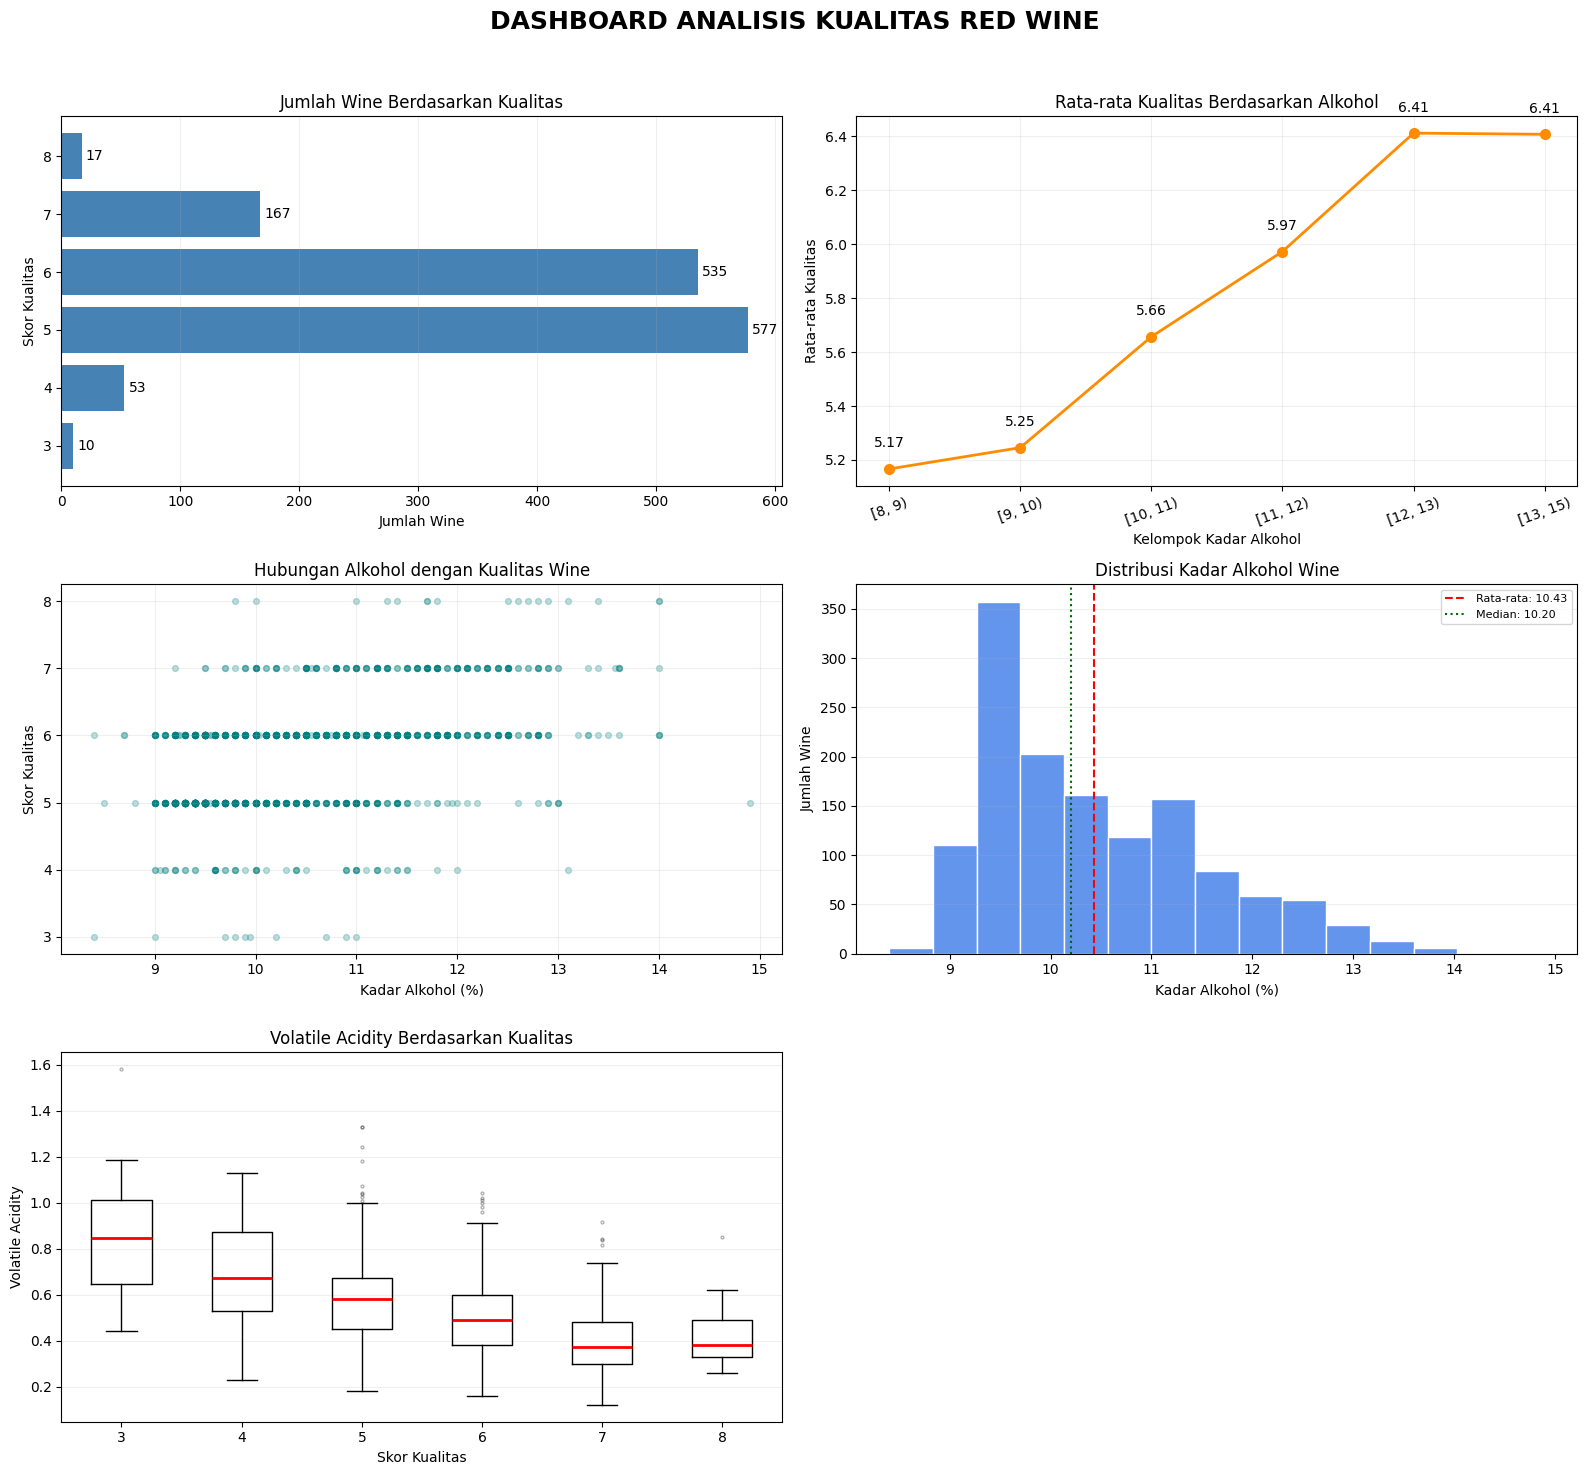

In [ ]:
# Tahap keenam — Membuat dashboard dengan empat grafik

import matplotlib.pyplot as plt
import pandas as pd

# Membuat dashboard dengan 5 grafik
fig, ax = plt.subplots(3, 2, figsize=(16, 15))

fig.suptitle(
    "DASHBOARD ANALISIS KUALITAS RED WINE",
    fontsize=18,
    fontweight="bold"
)

# Grafik 1 - Jumlah wine berdasarkan kualitas
jumlah = df["quality"].value_counts().sort_index()

bars = ax[0, 0].barh(
    jumlah.index.astype(str),
    jumlah.values,
    color="steelblue"
)

ax[0, 0].set_title("Jumlah Wine Berdasarkan Kualitas")
ax[0, 0].set_xlabel("Jumlah Wine")
ax[0, 0].set_ylabel("Skor Kualitas")
ax[0, 0].bar_label(bars, padding=3)
ax[0, 0].grid(axis="x", alpha=0.2)


# Grafik 2 - Rata-rata kualitas berdasarkan alkohol
rata_kualitas = df.groupby(
    "kelompok_alkohol",
    observed=False
)["quality"].mean().dropna()

ax[0, 1].plot(
    rata_kualitas.index.astype(str),
    rata_kualitas.values,
    marker="o",
    markersize=7,
    linewidth=2,
    color="darkorange"
)

for i, nilai in enumerate(rata_kualitas.values):
    ax[0, 1].text(
        i, nilai + 0.08,
        f"{nilai:.2f}",
        ha="center"
    )

ax[0, 1].set_title("Rata-rata Kualitas Berdasarkan Alkohol")
ax[0, 1].set_xlabel("Kelompok Kadar Alkohol")
ax[0, 1].set_ylabel("Rata-rata Kualitas")
ax[0, 1].tick_params(axis="x", rotation=20)
ax[0, 1].grid(alpha=0.2)


# Grafik 3 - Hubungan alkohol dengan kualitas
ax[1, 0].scatter(
    df["alcohol"],
    df["quality"],
    alpha=0.25,
    s=18,
    color="teal"
)

ax[1, 0].set_title("Hubungan Alkohol dengan Kualitas Wine")
ax[1, 0].set_xlabel("Kadar Alkohol (%)")
ax[1, 0].set_ylabel("Skor Kualitas")
ax[1, 0].set_yticks(sorted(df["quality"].unique()))
ax[1, 0].grid(alpha=0.2)


# Grafik 4 - Distribusi kadar alkohol
rata = df["alcohol"].mean()
median = df["alcohol"].median()

ax[1, 1].hist(
    df["alcohol"],
    bins=15,
    color="cornflowerblue",
    edgecolor="white"
)

ax[1, 1].axvline(
    rata,
    color="red",
    linestyle="--",
    label=f"Rata-rata: {rata:.2f}"
)

ax[1, 1].axvline(
    median,
    color="darkgreen",
    linestyle=":",
    label=f"Median: {median:.2f}"
)

ax[1, 1].set_title("Distribusi Kadar Alkohol Wine")
ax[1, 1].set_xlabel("Kadar Alkohol (%)")
ax[1, 1].set_ylabel("Jumlah Wine")
ax[1, 1].legend(fontsize=8)
ax[1, 1].grid(axis="y", alpha=0.2)


# Grafik 5 - Boxplot volatile acidity berdasarkan kualitas
skor = sorted(df["quality"].unique())

data_box = [
    df.loc[
        df["quality"] == nilai,
        "volatile acidity"
    ]
    for nilai in skor
]

ax[2, 0].boxplot(
    data_box,
    tick_labels=skor,
    showfliers=True,
    medianprops=dict(color="red", linewidth=2),
    flierprops=dict(
        marker="o",
        markersize=2,
        alpha=0.3
    )
)

ax[2, 0].set_title("Volatile Acidity Berdasarkan Kualitas")
ax[2, 0].set_xlabel("Skor Kualitas")
ax[2, 0].set_ylabel("Volatile Acidity")
ax[2, 0].grid(axis="y", alpha=0.2)


# Mengosongkan kotak grafik yang tidak digunakan
ax[2, 1].axis("off")

# Mengatur jarak antar grafik
plt.tight_layout(rect=[0, 0, 1, 0.96])

# Menampilkan dashboard
plt.show()



Insight 1 — Kualitas didominasi skor menengah
Skor 5 dan 6 merupakan kelompok terbesar. Ini menunjukkan bahwa sebagian besar pengamatan berada pada tingkat kualitas menengah menurut penilaian yang tersedia dalam dataset.


Insight 2 — Alkohol menunjukkan pola hubungan dengan kualitas
Rata-rata alkohol meningkat dari sekitar 9,89 pada kelompok kualitas 5 menjadi 11,49 pada kualitas 7. Ini merupakan hubungan dalam data, bukan bukti sebab-akibat.


Insight 3 — Acidity perlu diperhatikan
Rata-rata volatile acidity pada kualitas 5 lebih tinggi daripada kualitas 7. Pola ini dapat menjadi dasar untuk pemeriksaan lanjutan, tanpa menetapkan ambang kualitas hanya dari satu variabel.


Insight 4 — Ada nilai kimia yang tidak biasa
Sebanyak 55 data terdeteksi sebagai calon outlier pada kolom sulphates. Nilai tersebut perlu ditinjau, bukan langsung dihapus.
